# Estudios de ablación: Tarea 1 - Monedas

En este cuaderno auxiliar se justifican las decisiones de implementación tomadas en la primera tarea de la práctica. Se ha realizado un estudio de ablación para cada solución planteada, justificando así la utilidad de las opciones mantenidas.

## Organización

Para llevar a cabo el estudio, se han realizado distintas funciones que admiten su reconfiguración a través de sus parámetros. Una vez implementadas estas funciones, se pueden ir probando de forma independiente cada una de las soluciones. Por ejemplo, para probar distintos preprocesados:

```python
preprocess(img)                      # Comportamiento normal (usado en la práctica)
preprocess(img, blur="gaussiano")    # Comportamiento tras cambiar el filtro de ruido
preprocess(img, gamma=1)             # Comportamiento sin corrección gamma
```

Para facilitar la realización de los distintos experimentos, se ha implementado la función [`experiment`](#16-experimentos-evaluación-y-dibujo), que realiza el _pipeline_ completo sobre todas las imágenes reenviando los cambios indicados a la función que los usa.
<br>
Todos los parámetros han sido fijados a mano. Esto hace que el resultado sea optimista al no considerar una gran variedad de imágenes. Aun así, es una buena medida orientativa para comparar unas variantes con otras.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Datos de las monedas](#11-datos-de-las-monedas)
    - [1.2 Utilidades](#12-utilidades)
    - [1.3 Imágenes y valores reales](#13-imágenes-y-valores-reales)
    - [1.4 Transformaciones de la imagen](#14-transformaciones-de-la-imagen)
    - [1.5 Pipeline](#15-pipeline)
    - [1.6 Experimentos, evaluación y dibujo](#16-experimentos-evaluación-y-dibujo)
2. [Pruebas](#2-pruebas)
    - [2.1 Preprocesado](#21-preprocesado)
        - [2.1.1 Filtro de ruido](#211-filtro-de-ruido)
        - [2.1.2 Corrección gamma](#212-corrección-gamma)
        - [2.1.3 CLAHE](#213-clahe)
        - [2.1.4 Detección de bordes antes de Hough](#214-detección-de-bordes-antes-de-hough)
        - [2.1.5 Todas las combinaciones de preprocesado](#215-todas-las-combinaciones-de-preprocesado)
    - [2.2 Detección de círculos](#22-detección-de-círculos)
        - [2.2.1 Método de detección de círculos](#221-método-de-detección-de-círculos)
        - [2.2.2 Parámetros de Hough](#222-parámetros-de-hough)
        - [2.2.3 Filtro de radios grandes](#223-filtro-de-radios-grandes)
        - [2.2.4 Eliminación de duplicados](#224-eliminación-de-duplicados)
    - [2.3 Clasificación](#23-clasificación)
        - [2.3.1 Tolerancia de tamaño](#231-tolerancia-de-tamaño)
        - [2.3.2 Umbral de rojo adaptativo](#232-umbral-de-rojo-adaptativo)
        - [2.3.3 Zonas de la moneda para medir el color](#233-zonas-de-la-moneda-para-medir-el-color)
        - [2.3.4 Puntos característicos (ORB y SIFT)](#234-puntos-característicos-orb-y-sift)

## 1. Preparación

Con el fin de realizar un gran número de pruebas de la forma más eficaz posible, hemos generado un conjunto de funciones auxiliares.

### 1.1 Datos de las monedas

In [57]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt

Atributos de las 8 monedas de euro: nombre, valor, diámetro real en mm, metal y color del círculo que rodeará a la moneda detectada.

In [58]:
COINS = {
    "name":        np.array(["1cent", "2cent", "5cent", "10cent", "20cent", "50cent", "1eur", "2eur"]),
    "value":       np.array([0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00]),
    "diameter_mm": np.array([16.25, 18.75, 21.25, 19.75, 22.25, 24.25, 23.25, 25.75]),
    "metal":       np.array(["bronze", "bronze", "bronze", "gold", "gold", "gold", "1eur", "2eur"]),
    "color":       np.array([[0, 0, 255],
                             [0, 165, 255],
                             [0, 255, 255],
                             [0, 255, 191],
                             [0, 160, 0],
                             [255, 255, 0],
                             [255, 117, 44],
                             [240, 32, 160]]),
}

METAL = COINS["metal"]
COIN_DIAMETERS_MM = COINS["diameter_mm"]

### 1.2 Utilidades

In [59]:
img_rgb = cv2.cvtColor(cv2.imread('exercises/coins/monedas3.webp'), cv2.COLOR_BGR2RGB)

Muestra varias imágenes en una fila con Matplotlib (en gris si tienen un canal). Lo utilizaremos para poder comparar de forma visual los resultados intermedios.

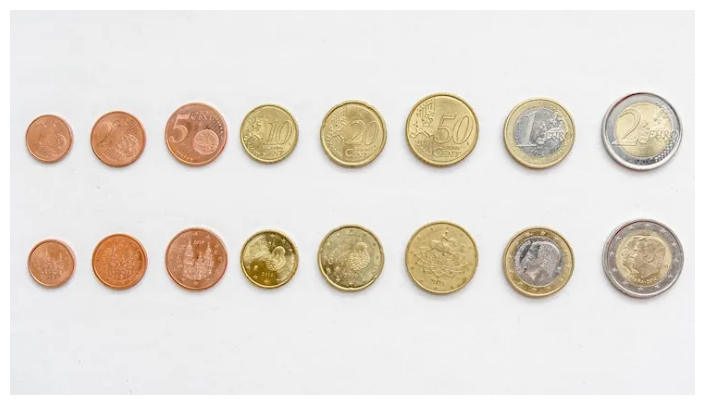

In [60]:
def show(images: list, size=(15, 5), titles=None):
    plt.figure(figsize=size)
    for i in range(len(images)):
        plt.subplot(1,len(images),i+1)
        plt.imshow(images[i], cmap='gray')
        if titles is not None:
            plt.title(titles[i])
        plt.axis('off')
    plt.show()

show([img_rgb])

Convierte una imagen RGB a escala de grises necesario para [Hough](#152-detección-de-círculos), [CLAHE](#141-intensidad), los umbralizados y los detectores de bordes, que trabajan sobre un solo canal.

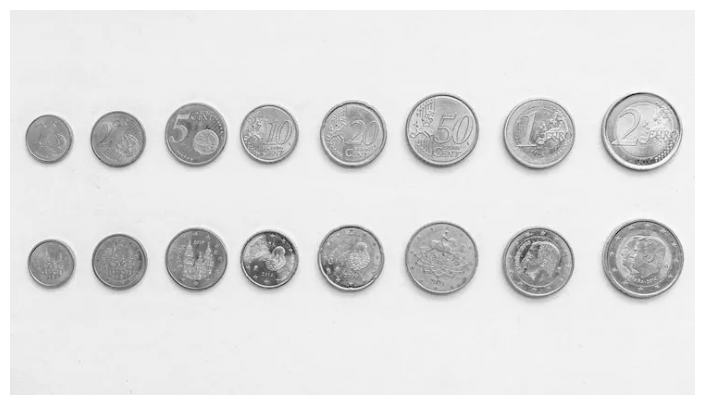

In [61]:
def to_gray(image):
    return cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

show([to_gray(img_rgb)])

Escribe texto sobre la imagen, modificándola en el sitio. Se usa para etiquetar cada moneda con su tipo.

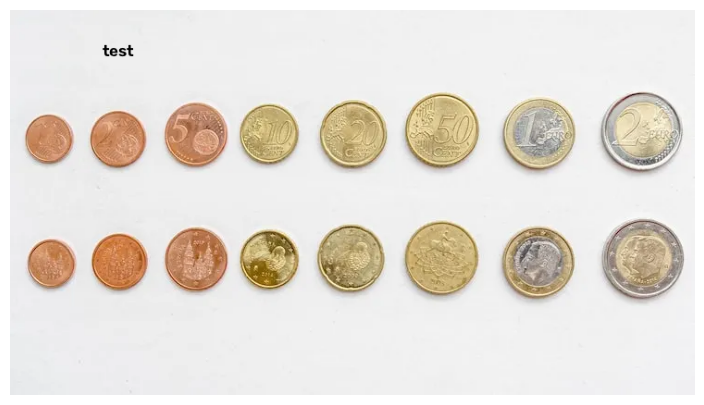

In [62]:
def put_text(img, text, org, scale=0.6):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), 4, cv2.LINE_AA)
    return img

show([put_text(img_rgb.copy(), "test", (100, 50))])

### 1.3 Imágenes y valores reales

Las pruebas se hacen sobre tres imágenes con condiciones distintas: una foto real con 19 monedas sobre una libreta (`monedas1.jpg`), y 2 imágenes ideales con distintas monedas sobre fondo blanco (`monedas2.jpg` y `monedas3.webp`).

Para cada imagen se indica cuántas monedas hay de cada tipo, en el mismo orden que [`COINS`](#11-datos-de-las-monedas).

monedas1: 19 monedas, 11.86 €
monedas2: 8 monedas, 3.88 €
monedas3: 16 monedas, 7.76 €


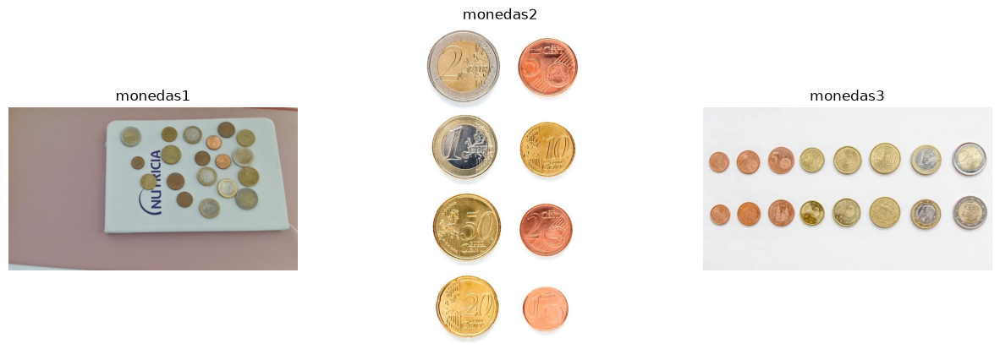

In [63]:
IMAGES = {
    "monedas1": "exercises/coins/monedas1.jpg",
    "monedas2": "exercises/coins/monedas2.jpg",
    "monedas3": "exercises/coins/monedas3.webp",
}

GROUND_TRUTH = {
    "monedas1": np.array([1, 5, 1, 2,  0,  3,  4, 3]),
    "monedas2": np.array([1, 1, 1, 1,  1,  1,  1, 1]),
    "monedas3": np.array([2, 2, 2, 2,  2,  2,  2, 2]),
}

IMAGE_SET = {name: cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB) for name, path in IMAGES.items()}

for name, truth in GROUND_TRUTH.items():
    print(f"{name}: {truth.sum()} monedas, {truth @ COINS['value']:.2f} €")
show(list(IMAGE_SET.values()), titles=list(IMAGE_SET))

### 1.4 Transformaciones de la imagen

#### 1.4.1 Intensidad

**CLAHE** Ecualiza la imagen por bloques (`tileGridSize`) y recorta el histograma (`clipLimit`) para no amplificar el ruido. Realza el relieve de las monedas cuando la iluminación no es uniforme.

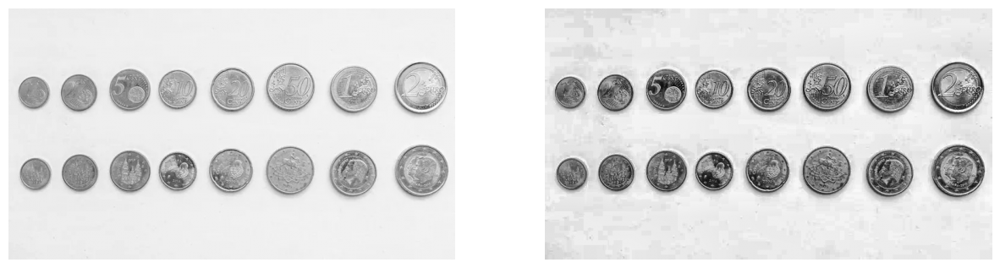

In [64]:
def apply_CLAHE(image, clipLimit: float= 5, tileGridSize: tuple = (8,8)):
    clahe = cv2.createCLAHE(clipLimit=clipLimit, tileGridSize=tileGridSize)
    return clahe.apply(image)
show([to_gray(img_rgb), apply_CLAHE(to_gray(img_rgb))])

**Corrección gamma**, que con `gamma < 1` oscurece los tonos más oscuros y mantiene los claros, aumentando el contraste entre las monedas y el fondo.

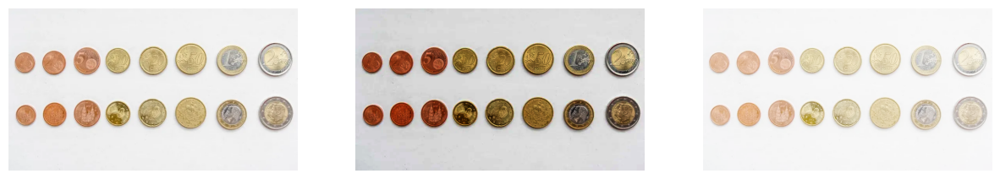

In [65]:
def gammaCorrection(src, gamma):
    invGamma = 1 / gamma

    table = [((i / 255) ** invGamma) * 255 for i in range(256)]
    table = np.array(table, np.uint8)

    return cv2.LUT(src, table)

show([img_rgb, gammaCorrection(img_rgb, 0.4), gammaCorrection(img_rgb, 2)])


#### 1.4.2 Reducción de ruido

Tanto [`gammaCorrection`](#141-intensidad) como [`CLAHE`](#141-intensidad) pueden amplificar el ruido de la imagen. Ese ruido se puede reducir con un filtro de suavizado con un _kernel_ suficientemente grande. Se comparan tres: mediana (`medianBlur`), gaussiano (`GaussianBlur`) y bilateral (`bilateralFilter`):

Comportamiento del filtro de mediana:

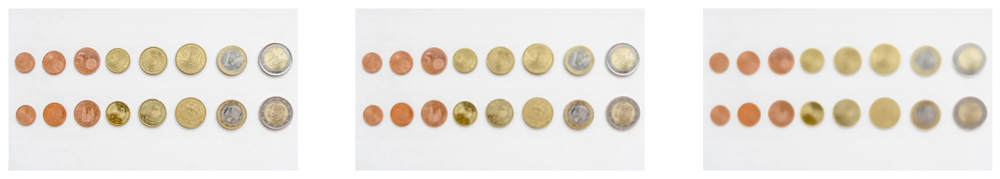

In [66]:
def median_blur(image, ksize=5):
    return cv2.medianBlur(image, ksize)

show([img_rgb, median_blur(img_rgb, 5), median_blur(img_rgb, 15)])

Comportamiento del filtro gaussiano:

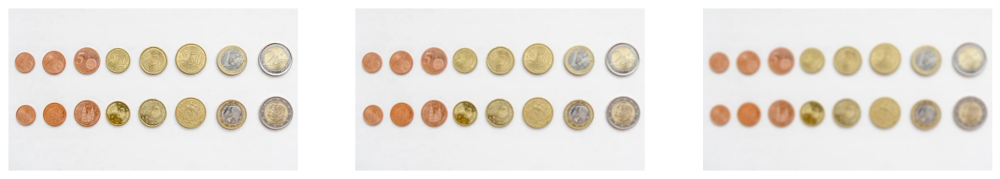

In [67]:
def gaussian_blur(image, ksize=(5, 5), sigma=0):
    return cv2.GaussianBlur(image, ksize, sigma)

show([img_rgb, gaussian_blur(img_rgb, (5, 5)), gaussian_blur(img_rgb, (15, 15))])

Comportamiento del filtro bilateral:

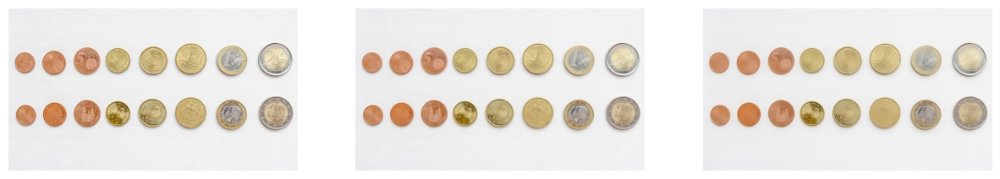

In [68]:
def bilateral_blur(image, d=21, sigma_color=75, sigma_space=999):
    return cv2.bilateralFilter(image, d, sigma_color, sigma_space)

show([img_rgb, bilateral_blur(img_rgb, 9), bilateral_blur(img_rgb, 21)])

#### 1.4.3 Detección de bordes

Detección con el operador Laplaciano, que previamente aplica un desenfoque gaussiano para reducir el ruido. Al basarse en la segunda derivada, responde a los cambios bruscos de intensidad:

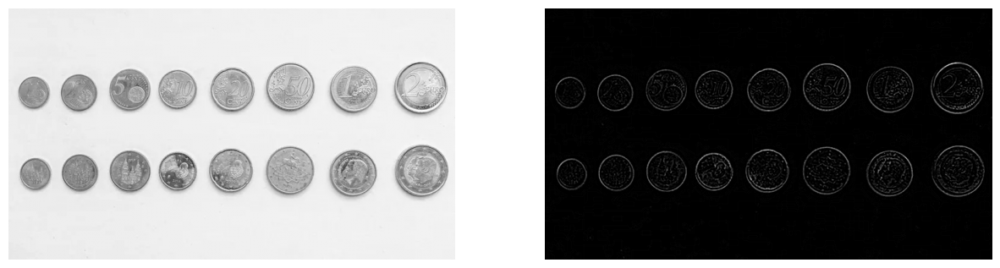

In [69]:
def border_detection_LoG(image):
    blur = cv2.GaussianBlur(image,(5,5),0)
    return cv2.Laplacian(blur,cv2.CV_8UC1)

show([to_gray(img_rgb), border_detection_LoG(to_gray(img_rgb))])

Detección con Canny, que incluye varias fases (gradiente con Sobel, supresión de no máximos e histéresis con dos umbrales). Da bordes finos de un píxel. Es el mismo detector usado internamente por [`HoughCircles`](#152-detección-de-círculos):

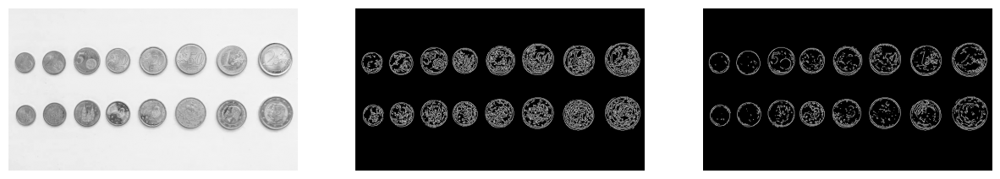

In [70]:
def border_detection_canny(image, low=50, high=150):
    return cv2.Canny(image, low, high)

show([to_gray(img_rgb), border_detection_canny(to_gray(img_rgb), 50, 150), border_detection_canny(to_gray(img_rgb), 180, 220)])

Detección con Sobel, que obtiene los contornos a partir de los gradientes:

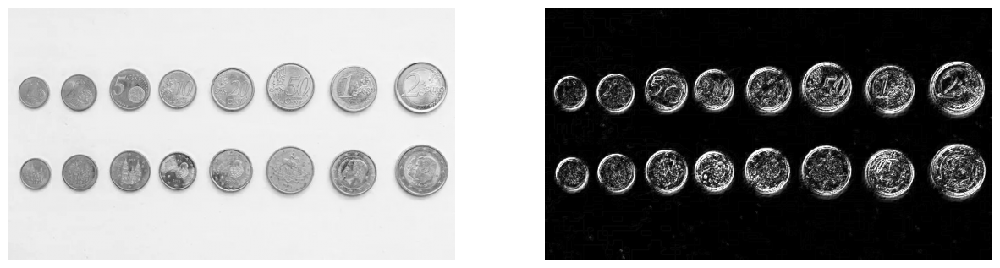

In [71]:
def apply_sobel(img):
    sobel = cv2.add(cv2.Sobel(img, cv2.CV_64F, 1, 0), 
                cv2.Sobel(img, cv2.CV_64F, 0, 1))
    return cv2.convertScaleAbs(sobel)

show([to_gray(img_rgb), apply_sobel(to_gray(img_rgb))])

#### 1.4.4 Detección de fondo (umbralizado)

Umbral adaptativo gaussiano, que facilita la separación aunque la iluminación varíe de una zona a otra:

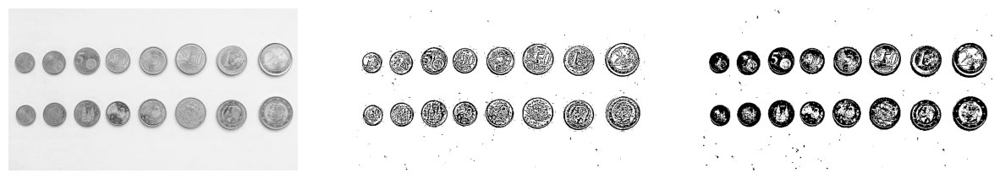

In [72]:
def background_detection_gauss(imagen, blockSize=61, constant=3):
    return cv2.adaptiveThreshold(
    imagen,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    blockSize,
    constant
    )

show([to_gray(img_rgb), background_detection_gauss(to_gray(img_rgb), 11), background_detection_gauss(to_gray(img_rgb), 61)])

Umbral de Otsu, calculado automáticamente como el valor que mejor separa el histograma en dos grupos. Funciona bien cuando la iluminación es uniforme, y cuando el fondo y las monedas tienen intensidades claramente distintas:

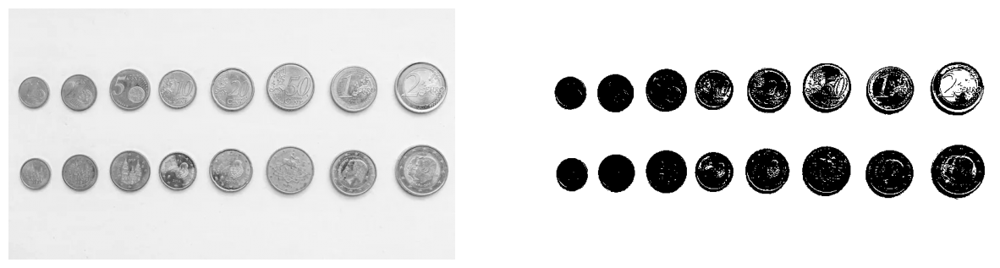

In [73]:
def background_detection_otsu(imagen):
    _, mask = cv2.threshold(imagen, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask

show([to_gray(img_rgb), background_detection_otsu(to_gray(img_rgb))])

### 1.5 Pipeline

Para contar el dinero de una imagen, siempre se siguen los mismos pasos. Antes de empezar, la imagen se [prepara](#151-preprocesado) para eliminar el ruido y resaltar las monedas. Después:

1. [Detección de círculos](#152-detección-de-círculos).

2. [Eliminación de círculos no candidatos](#152-detección-de-círculos), cuyo radio sea superior al doble del radio de las monedas más pequeñas.

3. [Eliminación de círculos duplicados](#152-detección-de-círculos), que corresponden a la misma moneda.

4. [Clasificación de las monedas según su color](#153-clasificación-por-color), que permite distinguir el metal de la moneda (e incluso indicar si es de 1€ o 2€).

5. Si se ha detectado alguna moneda, [encontrar la escala de la imagen](#154-clasificación-por-tamaño), y a partir de ella [clasificar cada moneda](#154-clasificación-por-tamaño) utilizando su diámetro.

#### 1.5.1 Preprocesado

Antes de enviar la imagen a [`hough_circles_detection`](#152-detección-de-círculos), se debe preprocesar la imagen, para eliminar el ruido sin perder puntos importantes.

El preprocesado siempre sigue el mismo orden: reducción de ruido -> corrección de color -> transformación a escala de grises -> ecualización -> detección de bordes: 

In [74]:
BLURS = {"ninguno": lambda image: image, "mediana": median_blur, "gaussiano": gaussian_blur, "bilateral": bilateral_blur}
GAMMAS = [0.4, 1, 2]
CLAHE_OPTIONS = [False, True]
EDGES = {"ninguno": None, "laplaciano": border_detection_LoG, "canny": border_detection_canny, "sobel": apply_sobel}


def preprocess(image, blur="bilateral", gamma=0.4, clahe=False, edges="ninguno"):
    prepared = to_gray(gammaCorrection(BLURS[blur](image), gamma))
    if clahe:
        prepared = apply_CLAHE(prepared)
    if EDGES[edges] is not None:
        prepared = EDGES[edges](prepared)
    return prepared

#### 1.5.2 Detección de círculos

Se han probado distintos métodos que detectan círculos sobre la imagen [preprocesada](#151-preprocesado).

**`HOUGH_GRADIENT_ALT`**, que según OpenCV suele proporcionar mejores resultados que `HOUGH_GRADIENT` convencional. En esta variante, `param1` es el umbral máximo del detector Canny que usa internamente, y `param2` indica lo perfecto que debe ser un círculo para aceptarlo (de 0 a 1).

In [75]:
def hough_circles_detection(image, min_radius=0, max_radius=0, param1=200, param2=0.8):
    circles = cv2.HoughCircles(
        image,
        cv2.HOUGH_GRADIENT_ALT,
        dp=1,
        minDist=40,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )
    if circles is None:
        return np.empty((0, 3), dtype=np.int32)
    return np.around(circles)[0].astype(np.int32)

**`HOUGH_GRADIENT`**. `param1` es el umbral máximo del detector Canny que usa internamente, y `param2` es el número mínimo de _votos_ que necesita un centro para aceptar el círculo:

In [76]:
def hough_gradient_detection(image, blur=11, param1=85, param2=40):
    circles = cv2.HoughCircles(
        cv2.medianBlur(image, blur),
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=30,
        param1=param1,
        param2=param2
    )
    if circles is None:
        return np.empty((0, 3), dtype=np.int32)
    return np.around(circles)[0].astype(np.int32)

**Detección por contornos**. Se separan las monedas del fondo con el [umbral de Otsu](#144-detección-de-fondo-umbralizado) y se buscan los contornos externos, cada uno comparado con su círculo mínimo envolvente.

In [77]:
def contour_detection(image, min_area=200, min_fill=0.8):
    _, mask = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    circles = []
    for contour in contours:
        area = cv2.contourArea(contour)
        (x, y), r = cv2.minEnclosingCircle(contour)
        if area >= min_area and area >= min_fill * np.pi * r ** 2:
            circles.append((x, y, r))
    if not circles:
        return np.empty((0, 3), dtype=np.int32)
    return np.around(circles).astype(np.int32)

Cualquiera de los detectores puede encontrar círculos que no son monedas, como sombras o bordes de objetos más grandes. Como todas las monedas tienen tamaños parecidos, se utiliza un percentil para eliminar radios demasiado grandes:

In [78]:
def filter_big_radius(circles, factor=2, q=0.1):
    if len(circles) == 0:
        return circles
    return circles[circles[:, 2] <= factor * np.quantile(circles[:, 2], q)]

Una misma moneda puede detectarse varias veces con círculos concéntricos. Por ello, se agrupan los círculos cuyos centros están demasiado cerca, manteniendo únicamente el de mayor radio.

In [79]:
def remove_duplicates(circles, min_dist_ratio=0.5):
    if len(circles) == 0:
        return []
    c = circles[np.argsort(-circles[:, 2])]
    dist = np.hypot(c[:, None, 0] - c[None, :, 0], c[:, None, 1] - c[None, :, 1])
    close = dist < min_dist_ratio * np.minimum(c[:, None, 2], c[None, :, 2])

    keep, removed = [], np.zeros(len(c), dtype=bool)
    for i in range(len(c)):
        if not removed[i]:
            keep.append(i)
            removed |= close[i]
    return c[keep]

#### 1.5.3 Clasificación por color

Antes de clasificar por color, se recorta la moneda, definiendo una _bounding box_ y poniendo a 0 (negro) todo lo que queda fuera del círculo. Sirve para analizar el color de cada moneda, aislándolas de su entorno.

In [80]:
def cut(image, circle):
  x, y, r = circle
  radio = r + 2

  h, w = image.shape[:2] 

  y1 = max(0, y - radio)
  y2 = min(h, y + radio)
  x1 = max(0, x - radio)
  x2 = min(w, x + radio)

  roi = image[y1:y2, x1:x2]
  mask = np.zeros(roi.shape, dtype=roi.dtype)

  color_blanco = (255, 255, 255) if len(image.shape) == 3 else 255
  cv2.circle(mask, (x - x1, y - y1), r, color_blanco, -1)

  moneda = cv2.bitwise_and(roi, mask)

  return moneda

Tras recortar la moneda con [`cut`](#153-clasificación-por-color), se analizan los colores de cada moneda. Se ha utilizado el espacio de color Lab, al permitir una mejor separación de las tonalidades amarillas y rojas. Se calculan tres medianas:

- **a\*** (tono rojo) de toda la moneda, hasta `outer` del radio.
- **b\*** (tono amarillo) del centro, hasta `centre_ratio` del radio.
- **b\*** del anillo exterior, entre `inner` y `outer` del radio.

*También se ha intentado utilizar otros mapas de color, como RGB y HSV, pero proporcionaron resultados erráticos.*

Con estas tres medidas se distinguen el cobre, el oro y las monedas de 1€ y 2€:

In [81]:
def coin_colors(img_lab, circle, outer=0.98, inner=0.78, centre_ratio=0.45):
    if img_lab is None or circle is None:
        return None
    moneda = cut(img_lab, circle)
    a, b = moneda[:, :, 1], moneda[:, :, 2]

    r = int(circle[2])
    centre_xy = (moneda.shape[1] // 2, moneda.shape[0] // 2)

    whole = np.zeros(moneda.shape[:2], dtype=np.uint8)
    cv2.circle(whole, centre_xy, int(r * outer), 255, -1)

    centre = np.zeros(moneda.shape[:2], dtype=np.uint8)
    cv2.circle(centre, centre_xy, int(r * centre_ratio), 255, -1)

    ring = np.zeros(moneda.shape[:2], dtype=np.uint8)
    cv2.circle(ring, centre_xy, int(r * outer), 255, -1)
    cv2.circle(ring, centre_xy, int(r * inner), 0, -1)

    return np.median(a[whole == 255]), np.median(b[centre == 255]), np.median(b[ring == 255])

Para distinguir el oro de la plata, se utiliza un umbral sobre el canal b* (tono amarillo):

In [82]:
SILVER_B = 142

Una vez diferenciada la plata, se distinguen el cobre y el oro en su tonalidad rojiza (valor de a\*). Como el tono depende en gran medida de la iluminación de la imagen, el umbral no es fijo: se calcula en cada imagen con el [método de Otsu](#144-detección-de-fondo-umbralizado):

In [83]:
def red_threshold(coins, default=138, min_gap=3):
    cents = [whole for whole, center, ring in coins
                   if center > SILVER_B and ring > SILVER_B]
    if len(cents) < 2:
        return default

    cents = np.array(cents, dtype=np.uint8)
    threshold, _ = cv2.threshold(cents, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    gold_cents, copper_cents = cents[cents <= threshold], cents[cents > threshold]
    if len(gold_cents) == 0 or len(copper_cents) == 0 or int(copper_cents.min()) - int(gold_cents.max()) < min_gap:
        return default

    return (int(gold_cents.max()) + int(copper_cents.min())) / 2

Finalmente, se calcula la probabilidad de que cada moneda sea de cada metal. Para resultar en una distribución probabilística, se utiliza la función sigmoide:

In [84]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

La probabilidad de cada metal se reparte a partes iguales entre sus monedas, de modo que se obtiene un vector de 8 probabilidades por moneda:

In [85]:
def color_probs(img_rgb, coins, adaptive_red=True, **ring):
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    coin_features = [coin_colors(img_lab, c, **ring) for c in coins]
    a_threshold = red_threshold(coin_features) if adaptive_red else 138

    probs = []
    for a, b_center, b_ring in coin_features:
        yellow_in, yellow_ring = sigmoid((b_center - SILVER_B) / 2), sigmoid((b_ring - SILVER_B) / 2)
        red = sigmoid((a - a_threshold) / 2)
        per_metal = {"bronze": yellow_in * yellow_ring * red,
                     "gold": yellow_in * yellow_ring * (1 - red),
                     "1eur": (1 - yellow_in) * yellow_ring,
                     "2eur": yellow_in * (1 - yellow_ring)}
        probs.append(np.array([per_metal[m] / np.sum(METAL == m) for m in METAL]))
    return np.array(probs)

#### 1.5.4 Clasificación por tamaño

Una vez distinguidos los colores de las monedas, se utiliza el tamaño para diferenciarlas. Para ello, se necesita un método que, dada una escala, calcula cuál es la moneda que más se ajusta a un diámetro concreto:

In [86]:
def closest_coin(radius_px, metal, px_per_mm):
    errors = np.abs(2 * radius_px / px_per_mm - COIN_DIAMETERS_MM) / COIN_DIAMETERS_MM
    errors[METAL != metal] = 9999999
    best = errors.argmin()
    return best, errors[best]

Para calcular la escala, se realiza una calibración automática. La escala se deduce de las monedas detectadas con la [clasificación por color](#153-clasificación-por-color), buscando la escala que minimiza el error:

In [87]:
def total_error(scale, real_coins):
    return sum(closest_coin(coin[0], coin[1], scale)[1] for coin in real_coins)

In [88]:
def find_px_per_mm(coins, colors):
    real_coins = [(int(coins[i][2]), METAL[colors[i].argmax()])
                  for i in range(len(coins)) if colors[i].sum() >= 0.5]

    scales = []
    for radius, metal in real_coins:
        for diameter in COIN_DIAMETERS_MM[METAL == metal]:
            scales.append(2 * radius / diameter)

    total_errors = [total_error(scale, real_coins) for scale in scales]

    return scales[np.argmin(total_errors)] if total_errors else None

La clasificación final de cada moneda combina el color del metal y el diámetro del círculo. Si las medidas no son fiables, se considera que el círculo no es una moneda:

In [89]:
def classify_coin(radius_px, colors, px_per_mm, max_error=0.12):
    if colors.sum() < 0.5:
        return None
    best, error = closest_coin(radius_px, METAL[colors.argmax()], px_per_mm)
    if error > max_error:
        return None
    return best

### 1.6 Experimentos, evaluación y dibujo

Ejecución de todos los pasos del _pipeline_ sobre una imagen. Devuelve las monedas detectadas y el tipo asignado a cada una. Cada parámetro cambia una de las decisiones y, por defecto, todos tienen el valor del _pipeline_ final:

In [90]:
def detect_circles(prepared, detector="alt", param1=200, param2=0.8, hough_blur=11):
    if detector == "gradient":
        return hough_gradient_detection(prepared, blur=hough_blur)
    if detector == "contornos":
        return contour_detection(prepared)
    return hough_circles_detection(prepared, param1=param1, param2=param2)


def run_pipeline(img_rgb, detector="alt", param1=200, param2=0.8, hough_blur=11, big_factor=2, dedupe=True,
                 dup_ratio=0.5, max_error=0.12, adaptive_red=True, outer=0.98, inner=0.78, **preprocess_options):
    circles = detect_circles(preprocess(img_rgb, **preprocess_options), detector, param1, param2, hough_blur)
    if big_factor is not None:
        circles = filter_big_radius(circles, factor=big_factor)
    coins = remove_duplicates(circles, dup_ratio) if dedupe else circles
    if len(coins) == 0:
        return coins, []

    probabilities = color_probs(img_rgb, coins, adaptive_red, outer=outer, inner=inner)
    px_per_mm = find_px_per_mm(coins, probabilities)
    if px_per_mm is None:
        return coins, [None] * len(coins)

    return coins, [classify_coin(c[2], p, px_per_mm, max_error) for c, p in zip(coins, probabilities)]

Para cada experimento, se calcula el acierto y se dibujan las monedas sobre las imágenes originales:

In [91]:
def count_by_type(kinds):
    return np.bincount([k for k in kinds if k is not None], minlength=len(COINS["name"]))


def image_scores(kinds, truth):
    counts = count_by_type(kinds)
    return {"acc": np.minimum(counts, truth).sum() / truth.sum(),
            "euros": float(counts @ COINS["value"]),
            "real_euros": float(truth @ COINS["value"])}


def experiment(name, images=IMAGE_SET, run=run_pipeline, **options):
    row, detections = {"var": name}, {}
    for img_name, img in images.items():
        coins, kinds = run(img, **options)
        detections[img_name] = {"coins": coins, "kinds": kinds, **image_scores(kinds, GROUND_TRUTH[img_name])}
        row[f"det{img_name[-1]}"] = len(coins)
        row[f"acc{img_name[-1]}"] = detections[img_name]["acc"]

    row["accuracy"] = np.mean([d["acc"] for d in detections.values()])
    row["error €"] = sum(abs(d["euros"] - d["real_euros"]) for d in detections.values())
    return {"row": row, "detections": detections, "images": images}


def renamed(result, name):
    return {**result, "row": {**result["row"], "var": name}}

           var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
Pipeline final     1.000      0.00        20     1.000         8     1.000        16     1.000


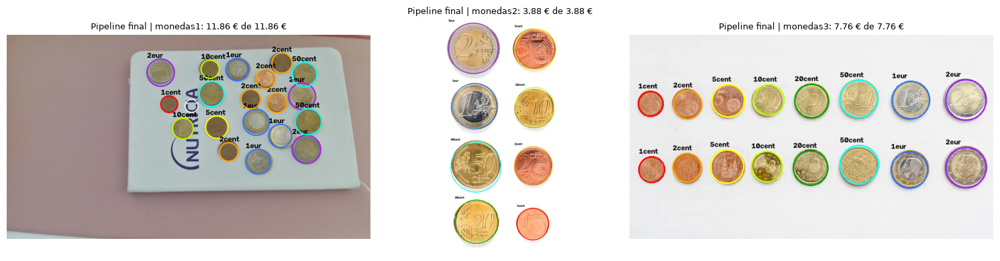

In [92]:
COLUMNS = ["accuracy", "error €"] + [f"{k}{name[-1]}" for name in IMAGES for k in ("det", "acc")]


def results_table(results):
    width = max(len(r["row"]["var"]) for r in results)
    lines = [f"{'var':>{width}}" + "".join(f"{c:>10}" for c in COLUMNS)]
    for r in results:
        values = [f"{r['row'][c]:>10.2f}" if c == "error €" else
                  f"{r['row'][c]:>10.3f}" if isinstance(r["row"][c], float) else
                  f"{r['row'][c]:>10}" for c in COLUMNS]
        lines.append(f"{r['row']['var']:>{width}}" + "".join(values))
    return "\n".join(lines)


def draw_detections(img, coins, kinds):
    det_img = img.copy()
    scale = img.shape[1] / 1500
    for (x, y, r), kind in zip(coins, kinds):
        center, r = (int(x), int(y)), int(r)
        if kind is None:
            cv2.circle(det_img, center, r, (255, 255, 255), max(2, int(3 * scale)))
            continue
        cv2.circle(det_img, center, r, COINS["color"][kind][::-1].tolist(), max(2, int(4 * scale)))   # BGR -> RGB
        put_text(det_img, COINS["name"][kind], (center[0] - r, center[1] - r - 6), max(0.4, scale))
    return det_img


def plot_detections(results):
    names = list(results[0]["images"])
    plt.figure(figsize=(15, 4 * len(results)))
    for i, r in enumerate(results):
        for j, img_name in enumerate(names):
            d = r["detections"][img_name]
            plt.subplot(len(results), len(names), len(names) * i + j + 1)
            plt.imshow(draw_detections(r["images"][img_name], d["coins"], d["kinds"]))
            plt.title(f"{r['row']['var']} | {img_name}: {d['euros']:.2f} € de {d['real_euros']:.2f} €", fontsize=9)
            plt.axis("off")
    plt.tight_layout()
    plt.show()


def show_results(results):
    print(results_table(results))
    plot_detections(results)


FINAL = experiment("Pipeline final")
show_results([FINAL])

Se observa que el _pipeline_ final clasifica bien todas las monedas de las tres imágenes y cuenta exactamente el dinero real (`error €` = 0).

## 2. Pruebas

Cada experimento muestra una tabla y una figura:

- **Tabla:** una fila por variante, con su acierto medio (`accuracy`), el dinero mal contado en las tres imágenes (`error €`) y, para cada imagen, el número de monedas detectadas (`det1`, `det2`, `det3`) y su acierto (`acc1`, `acc2`, `acc3`). Como referencia, hay 19, 8 y 16 monedas reales.
- **Figura:** las detecciones de cada variante sobre las tres imágenes, con el dinero contado frente al real en el título.

### 2.1 Preprocesado

#### 2.1.1 Filtro de ruido

Compara el filtro bilateral con el gaussiano, la mediana y no aplicar ningún filtro:

          var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
    Bilateral     1.000      0.00        20     1.000         8     1.000        16     1.000
Gaussiano 5x5     0.947      0.33        20     0.842         8     1.000        16     1.000
    Mediana 5     0.912      0.37        20     0.737         8     1.000        16     1.000
   Sin filtro     0.912      1.24        19     0.737         8     1.000        16     1.000


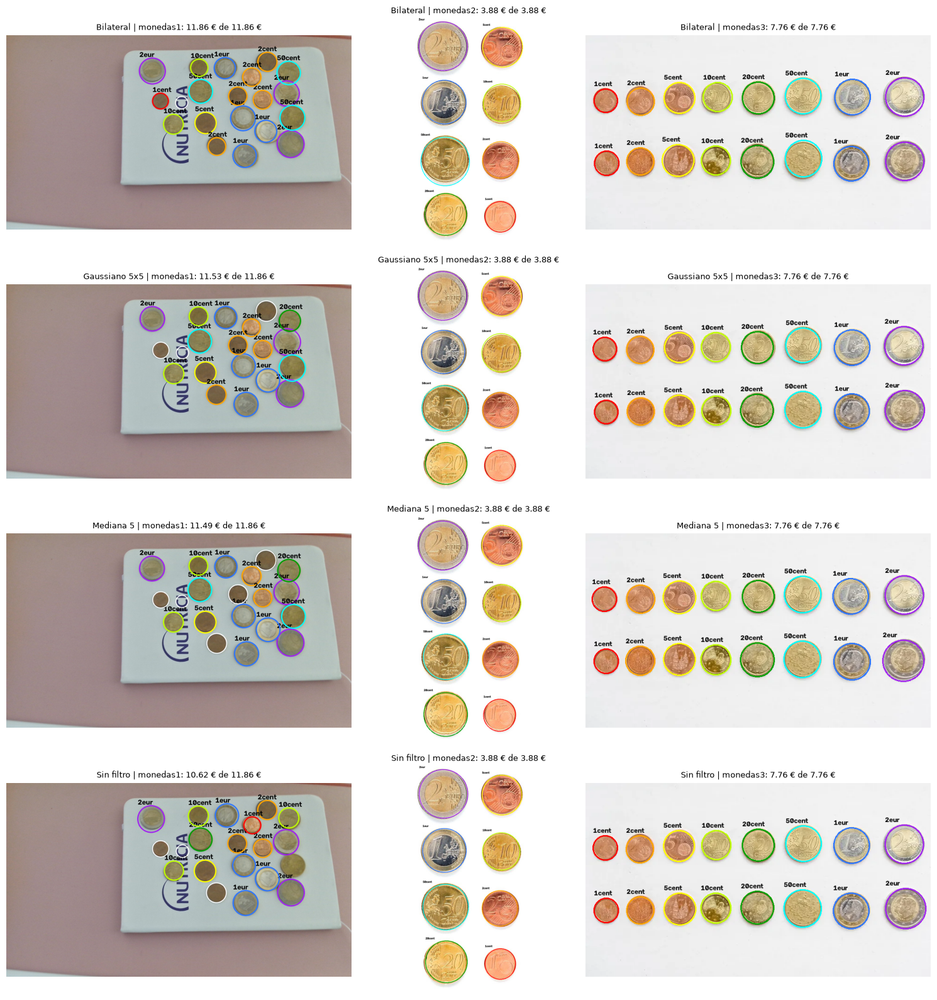

In [93]:
show_results([renamed(FINAL, "Bilateral"),
              experiment("Gaussiano 5x5", blur="gaussiano"),
              experiment("Mediana 5", blur="mediana"),
              experiment("Sin filtro", blur="ninguno")])

Se elige el **filtro bilateral**, el único que acierta todas las monedas. Especialmente en la foto real (`monedas1`), el filtro bilateral reduce el ruido sin difuminar el borde de las monedas, que es justo lo que necesita Hough para encontrarlas.

#### 2.1.2 Corrección gamma

Compara distintos niveles de corrección gamma:

                     var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
               Gamma 0.4     1.000      0.00        20     1.000         8     1.000        16     1.000
Sin corrección (gamma 1)     0.860      5.69        16     0.579         8     1.000        16     1.000
                 Gamma 2     0.891      3.64        16     0.737         8     1.000        16     0.938


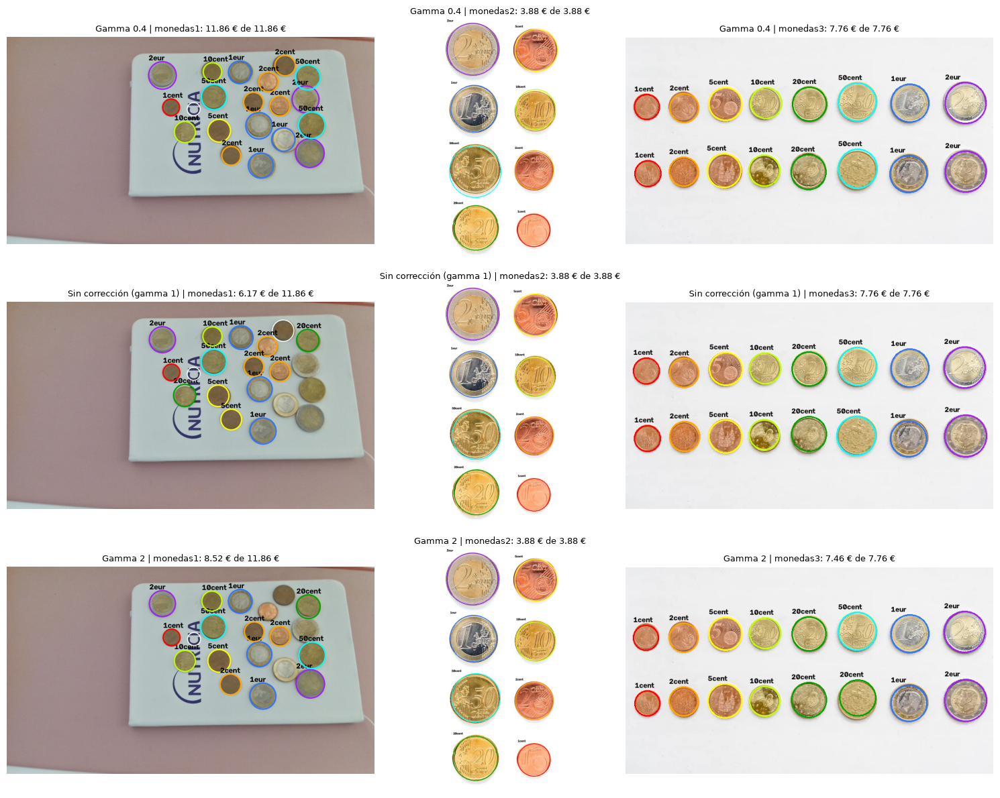

In [94]:
show_results([renamed(FINAL, "Gamma 0.4"),
              experiment("Sin corrección (gamma 1)", gamma=1),
              experiment("Gamma 2", gamma=2)])

Se utiliza un valor de **gamma = 0,4**. Con corrección por exceso o por defecto se pierden monedas de la foto real.

#### 2.1.3 CLAHE

Compara aplicar o no la ecualización adaptativa del histograma antes de buscar los círculos:

      var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
Sin CLAHE     1.000      0.00        20     1.000         8     1.000        16     1.000
Con CLAHE     0.578      5.76        19     0.421         8     0.750        16     0.562


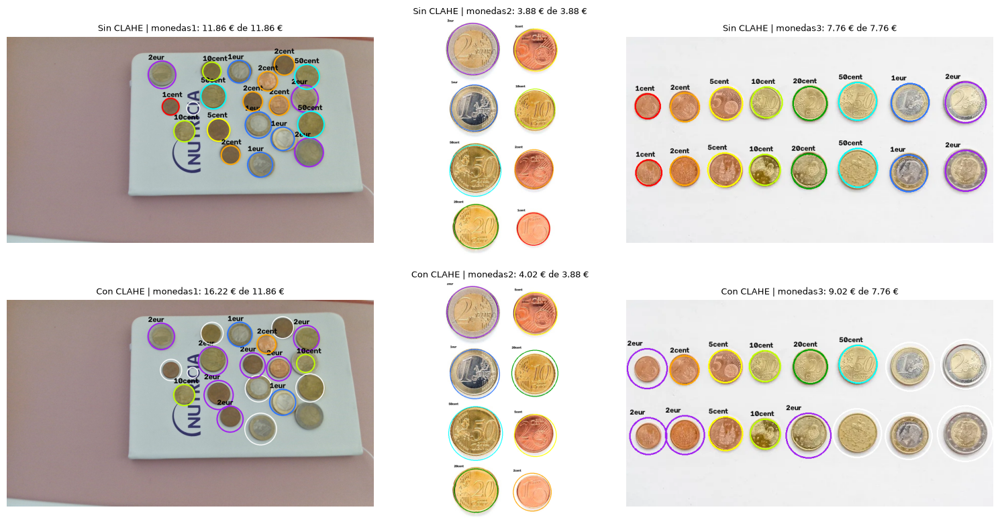

In [95]:
show_results([renamed(FINAL, "Sin CLAHE"),
              experiment("Con CLAHE", clahe=True)])

Se descarta **CLAHE**, al empeorar el rendimiento en las 3 imágenes. El ecualizador también realza los bordes internos de las monedas, lo que disminuye la fiabilidad de Hough.

#### 2.1.4 Detección de bordes antes de Hough

Evalúa distintas configuraciones de partida sobre el método de Hough, con varios tipos de detección de bordes:

                   var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
Sin detector de bordes     1.000      0.00        20     1.000         8     1.000        16     1.000
            Laplaciano     0.719     10.56         5     0.158         8     1.000        16     1.000
                 Canny     0.000     23.50         0     0.000         0     0.000         0     0.000
                 Sobel     0.685      6.65        11     0.368         8     0.750        16     0.938


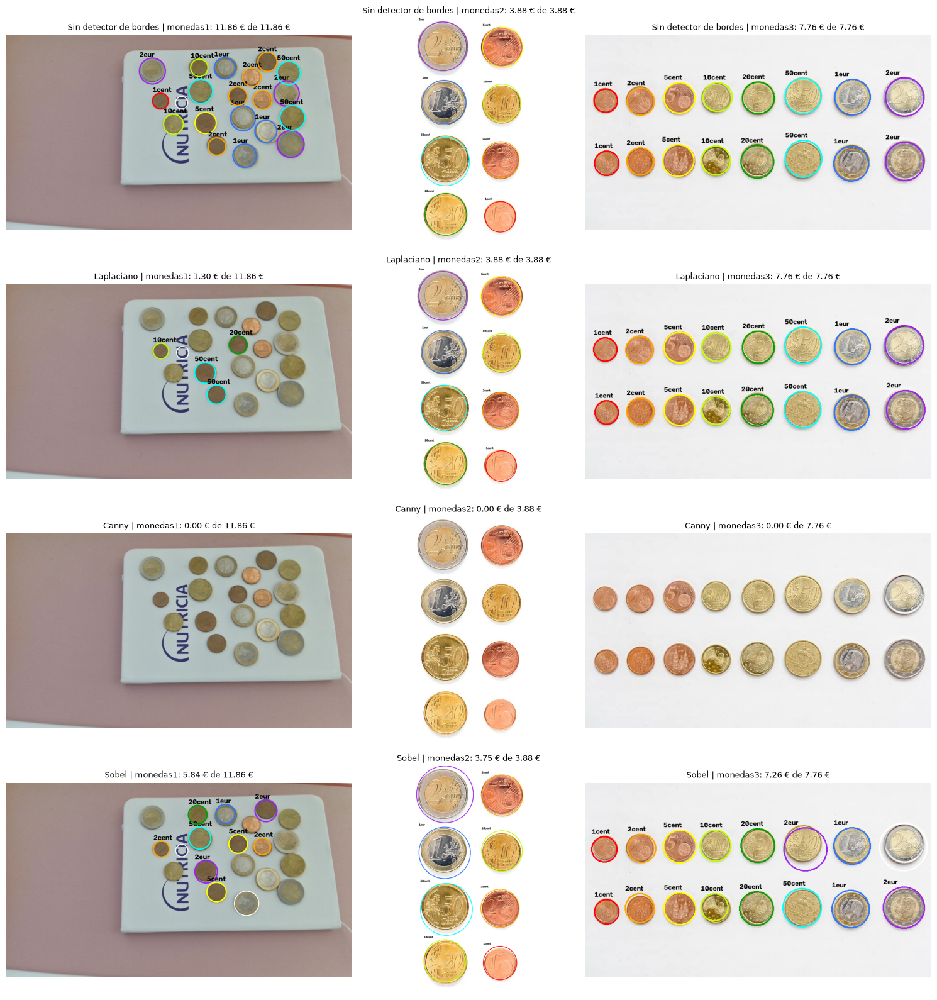

In [96]:
show_results([renamed(FINAL, "Sin detector de bordes"),
              experiment("Laplaciano", edges="laplaciano"),
              experiment("Canny", edges="canny"),
              experiment("Sobel", edges="sobel")])

Se concluye que el preprocesamiento que mejor rendimiento proporciona es la **imagen en gris, sin detector de bordes previo**. `HoughCircles` ya aplica Canny internamente, por lo que realizar previamente una detección de bordes debilita el cálculo de gradientes.

#### 2.1.5 Todas las combinaciones de preprocesado

Se evalúan todas las distintas posibilidades de preprocesado de la imagen:

                                              var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
bilateral, gamma 0.4, clahe False, bordes ninguno     1.000      0.00        20     1.000         8     1.000        16     1.000
    mediana, gamma 1, clahe False, bordes ninguno     0.965      0.03        20     0.895         8     1.000        16     1.000
  gaussiano, gamma 1, clahe False, bordes ninguno     0.965      0.32        20     0.895         8     1.000        16     1.000
gaussiano, gamma 0.4, clahe False, bordes ninguno     0.947      0.33        20     0.842         8     1.000        16     1.000
    mediana, gamma 2, clahe False, bordes ninguno     0.930      2.62        19     0.789         8     1.000        16     1.000
  mediana, gamma 0.4, clahe False, bordes ninguno     0.912      0.37        20     0.737         8     1.000        16     1.000
  ninguno, gamma 0.4, clahe False, bordes ninguno     0.912      1.24        19     0.737 

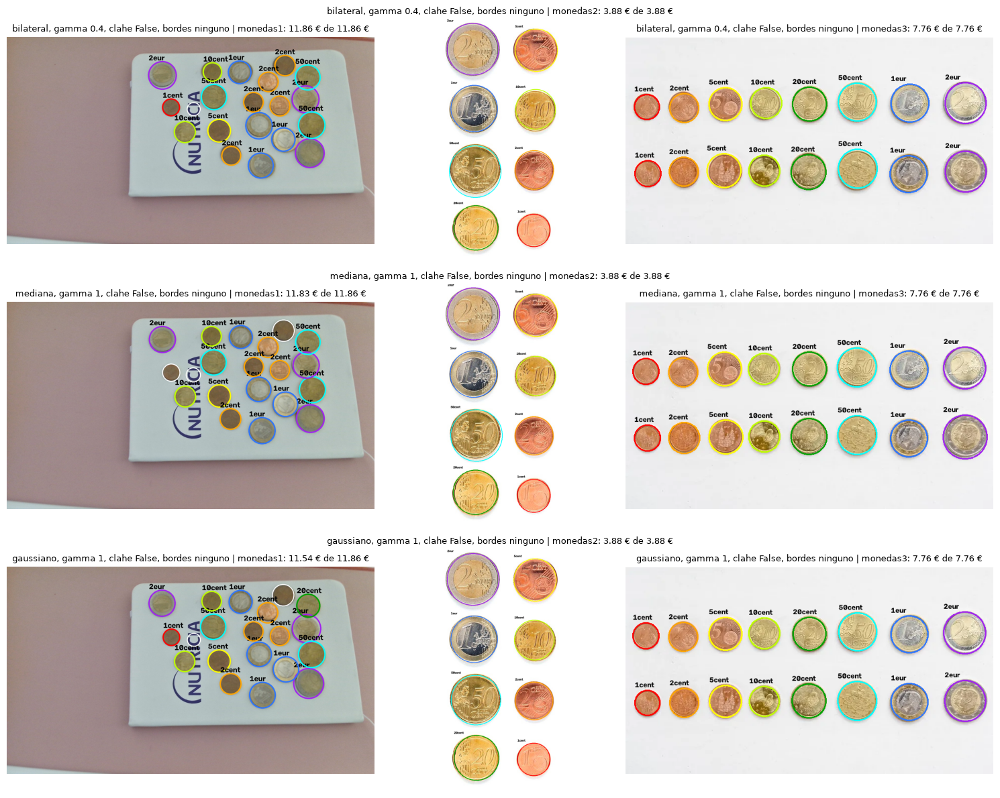

In [97]:
combinations = [experiment(f"{blur}, gamma {gamma}, clahe {clahe}, bordes {edges}",
                           blur=blur, gamma=gamma, clahe=clahe, edges=edges)
                for blur in BLURS for gamma in GAMMAS for clahe in CLAHE_OPTIONS for edges in EDGES]
combinations.sort(key=lambda r: (-r["row"]["accuracy"], r["row"]["error €"]))

print(results_table(combinations[:10]))
plot_detections(combinations[:3])

La combinación utilizada es la que proporciona mejor rendimiento: **bilateral -> gamma 0,4 -> no CLAHE -> no detector de bordes**.

### 2.2 Detección de círculos

#### 2.2.1 Método de detección de círculos

Compara distintos métodos de [detección de círculos](#152-detección-de-círculos):

                       var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
        HOUGH_GRADIENT_ALT     1.000      0.00        20     1.000         8     1.000        16     1.000
HOUGH_GRADIENT, mediana 11     0.861      4.09        25     0.895        14     0.750        16     0.938
HOUGH_GRADIENT, mediana 27     0.871      3.59        19     0.737         8     0.875        16     1.000
                 Contornos     0.737      8.71         7     0.211         8     1.000        16     1.000


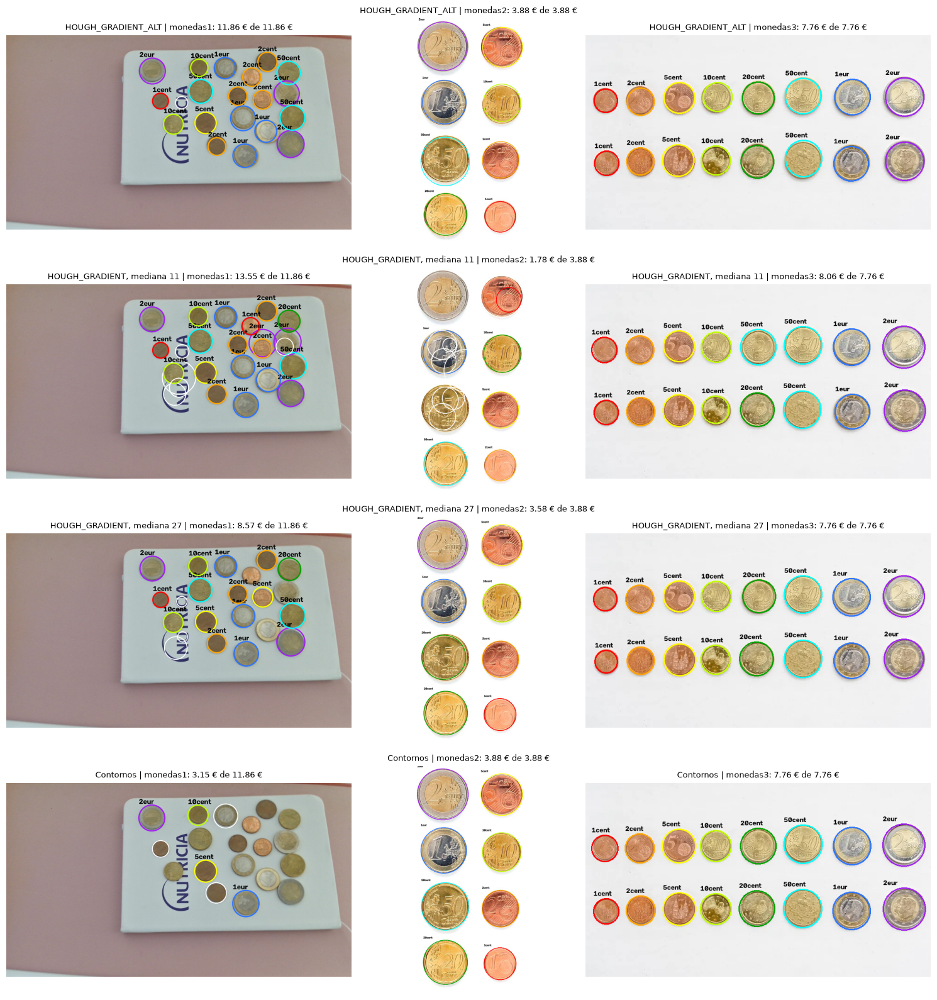

In [101]:
show_results([renamed(FINAL, "HOUGH_GRADIENT_ALT"),
              experiment("HOUGH_GRADIENT, mediana 11", detector="gradient", hough_blur=11, blur="ninguno", gamma=1),
              experiment("HOUGH_GRADIENT, mediana 27", detector="gradient", hough_blur=27, blur="ninguno", gamma=1),
              experiment("Contornos", detector="contornos")])

Se utiliza **`HOUGH_GRADIENT_ALT`**, el único que acierta todas las monedas. Con `HOUGH_GRADIENT` el resultado depende mucho del suavizado: un kernel muy pequeño genera muchos falsos positivos, y uno demasiado grande muchos falsos negativos. La detección por contornos funciona en las imágenes con fondo uniforme, pero en la foto real no proporciona un buen rendimiento.

#### 2.2.2 Parámetros de Hough

Compara distintos valores de `param1` y `param2` sobre `HOUGH_GRADIENT_ALT`:

                    var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
 param1=200, param2=0.8     1.000      0.00        20     1.000         8     1.000        16     1.000
param1=190, param2=0.75     0.906      2.50        18     0.842         8     0.875        16     1.000
 param1=190, param2=0.7     0.906      2.22        18     0.842         8     0.875        16     1.000
param1=220, param2=0.85     0.930      3.04        19     0.789         8     1.000        16     1.000


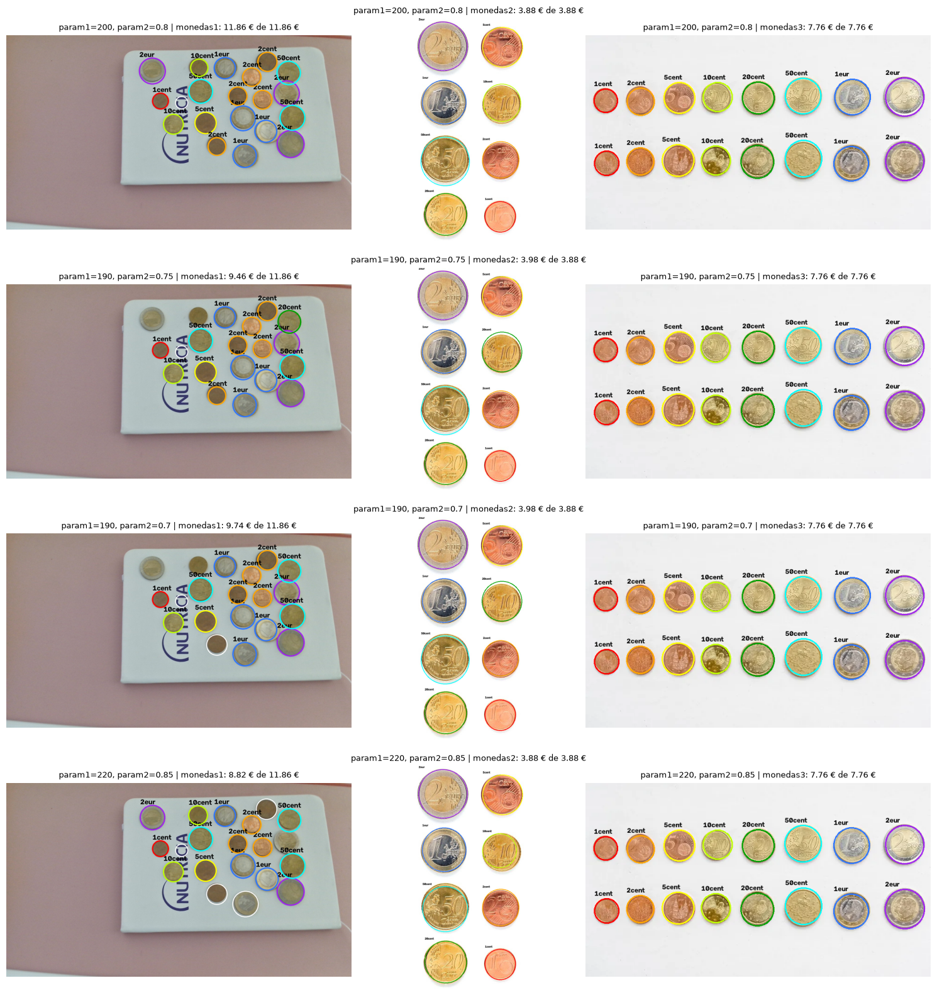

In [98]:
show_results([renamed(FINAL, "param1=200, param2=0.8"),
              experiment("param1=190, param2=0.75", param1=190, param2=0.75),
              experiment("param1=190, param2=0.7", param1=190, param2=0.7),
              experiment("param1=220, param2=0.85", param1=220, param2=0.85)])

Se utilizan **`param1=200` y `param2=0.8`**. Cualquier modificación por exceso o por defecto proporciona un peor rendimiento.

#### 2.2.3 Filtro de radios grandes

Compara distintas medidas de factor/percentil para descartar los círculos con radio demasiado grande:

               var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
  2 × percentil 10     1.000      0.00        20     1.000         8     1.000        16     1.000
        Sin filtro     1.000      0.00        20     1.000         8     1.000        16     1.000
1.5 × percentil 10     0.772      8.46        12     0.316         8     1.000        16     1.000
  3 × percentil 10     1.000      0.00        20     1.000         8     1.000        16     1.000


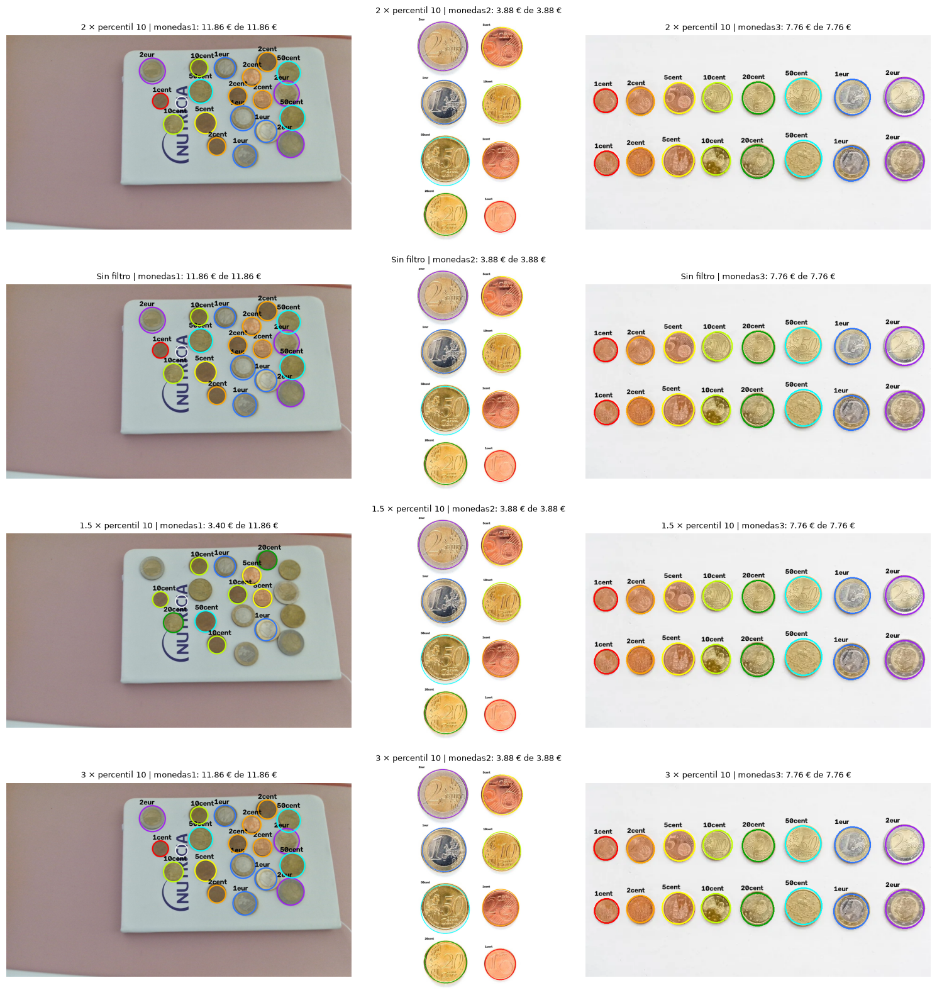

In [99]:
show_results([renamed(FINAL, "2 × percentil 10"),
              experiment("Sin filtro", big_factor=None),
              experiment("1.5 × percentil 10", big_factor=1.5),
              experiment("3 × percentil 10", big_factor=3)])

Se utiliza el margen **2**, que descarta los círculos demasiado grandes sin eliminar monedas reales (con 1,5 ya se pierden monedas de `monedas1`). En estas tres imágenes da el mismo resultado que no filtrar, por lo que aquí no se aprecia su beneficio; se mantiene como protección frente a círculos que no son monedas, como sombras o bordes de objetos más grandes.

#### 2.2.4 Eliminación de duplicados

Compara distintas medidas de distancia para la eliminación de duplicados:

                    var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
            Medio radio     1.000      0.00        20     1.000         8     1.000        16     1.000
Sin eliminar duplicados     1.000      0.11        22     1.000         8     1.000        17     1.000
          0.3 del radio     1.000      0.00        20     1.000         8     1.000        16     1.000
          0.8 del radio     1.000      0.00        20     1.000         8     1.000        16     1.000


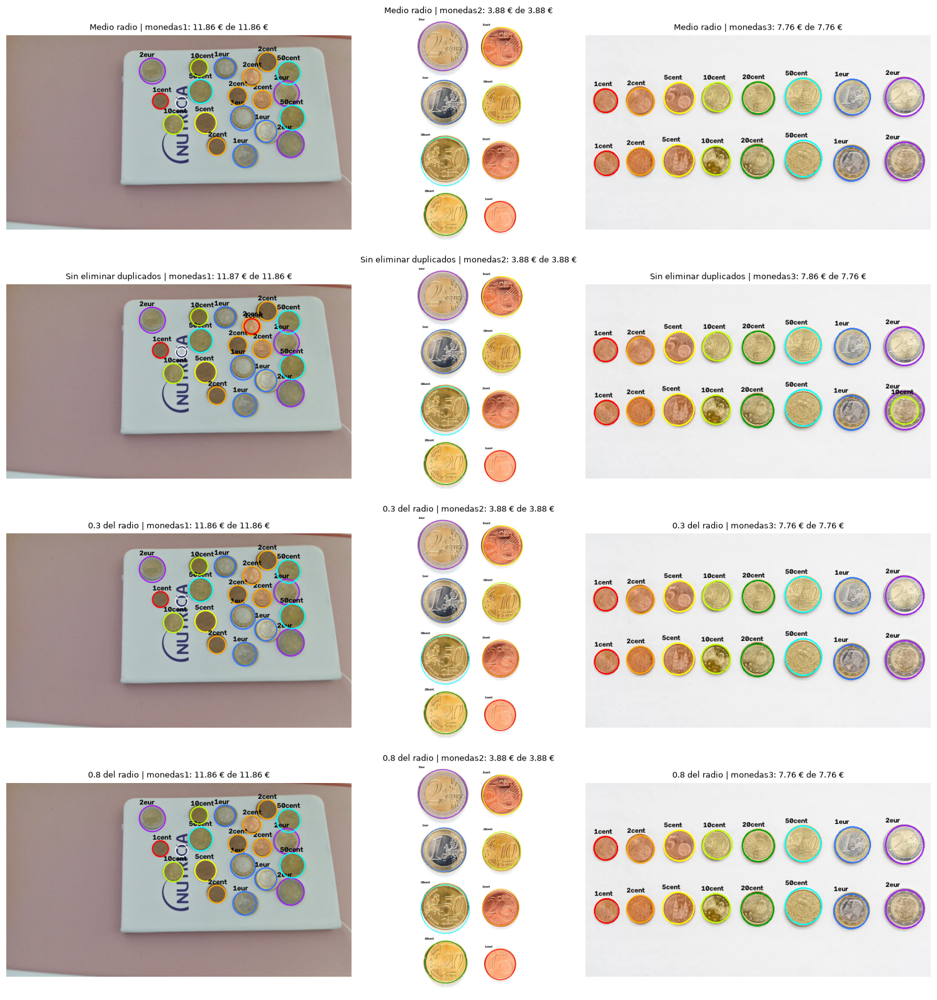

In [100]:
show_results([renamed(FINAL, "Medio radio"),
              experiment("Sin eliminar duplicados", dedupe=False),
              experiment("0.3 del radio", dup_ratio=0.3),
              experiment("0.8 del radio", dup_ratio=0.8)])

No eliminar duplicados genera varias detecciones sobre la misma moneda. Como tanto 0,3 como 0,8 proporcionan buenos resultados, se decide utilizar **0,5 * radio** como medida intermedia.

### 2.3 Clasificación

#### 2.3.1 Tolerancia de tamaño

Compara el error máximo de tamaño con el que se acepta una moneda:

       var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
Hasta 12 %     1.000      0.00        20     1.000         8     1.000        16     1.000
 Hasta 5 %     0.888      4.60        20     0.789         8     0.875        16     1.000
 Hasta 8 %     0.965      1.10        20     0.895         8     1.000        16     1.000
Hasta 20 %     1.000      0.00        20     1.000         8     1.000        16     1.000


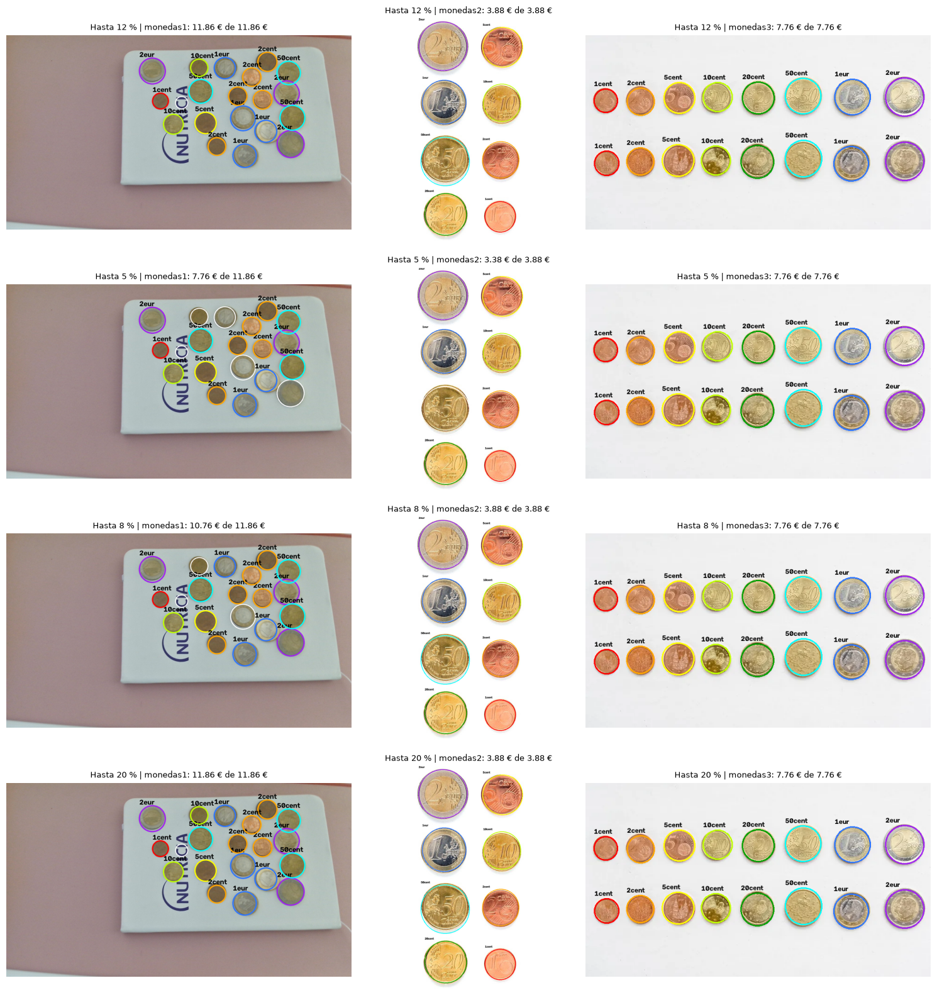

In [102]:
show_results([renamed(FINAL, "Hasta 12 %"),
              experiment("Hasta 5 %", max_error=0.05),
              experiment("Hasta 8 %", max_error=0.08),
              experiment("Hasta 20 %", max_error=0.20)])

Se mantiene una tolerancia del **12 %**, que permite ajustar todas las monedas con un cierto margen.

#### 2.3.2 Umbral de rojo adaptativo

Compara usar un umbral fijo o adaptativo para separar las monedas de cobre y oro en [`red_threshold`](#153-clasificación-por-color):

                     var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
Umbral adaptativo (Otsu)     1.000      0.00        20     1.000         8     1.000        16     1.000
       Umbral fijo (138)     0.871      0.46        20     0.737         8     0.875        16     1.000


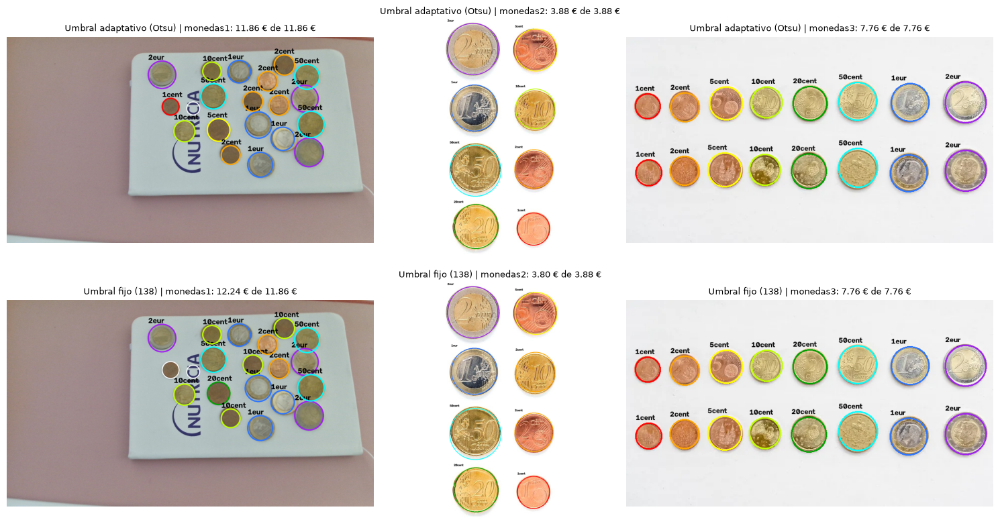

In [103]:
show_results([renamed(FINAL, "Umbral adaptativo (Otsu)"),
              experiment("Umbral fijo (138)", adaptive_red=False)])

Se mantiene el **umbral adaptativo**. Con un umbral fijo, la iluminación y tonalidad de las imágenes impiden el ajuste para varios casos. Calcularlo en cada imagen con Otsu se adapta a esas condiciones.

#### 2.3.3 Zonas de la moneda para medir el color

Compara varias distinciones entre centro y anillo sobre [`coin_colors`](#153-clasificación-por-color), para encontrar monedas de 1€ y 2€:

           var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
Anillo 78-98 %     1.000      0.00        20     1.000         8     1.000        16     1.000
Anillo 72-92 %     1.000      0.00        20     1.000         8     1.000        16     1.000


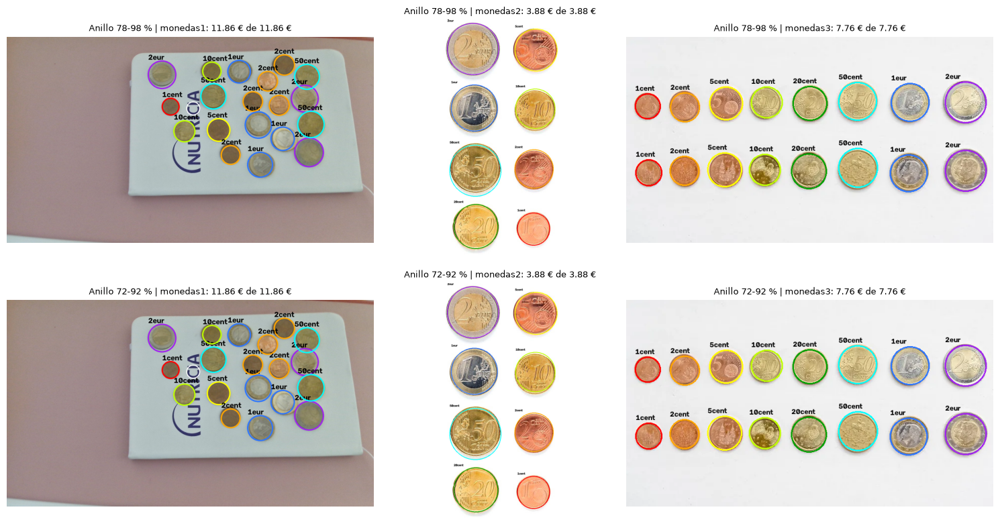

In [104]:
show_results([renamed(FINAL, "Anillo 78-98 %"),
              experiment("Anillo 72-92 %", outer=0.92, inner=0.72)])

En estas imágenes las dos zonas dan el mismo resultado. Se mantiene el mayor rango **78 % al 98 %**, al proporcionar más holgura en la clasificación.

#### 2.3.4 Puntos característicos (ORB y SIFT)

Se prueba otra forma de clasificar las monedas: en lugar de usar su color y su tamaño, se identifican puntos característicos de las monedas.

ORB o SIFT buscan detalles del dibujo (esquinas, relieves) y los emparejan con los de imágenes de referencia. Solo se aceptan las parejas claras, en las que el mejor candidato es bastante mejor que el segundo (`RATIO`).

RANSAC busca el giro, la escala y el desplazamiento que mejor llevan la moneda sobre la referencia, y cuenta cuántas parejas encajan con él (_inliers_). La moneda se asigna a la referencia con más _inliers_, y se queda sin clasificar si ninguna llega a `MIN_INLIERS`.

Los círculos son los mismos que en el _pipeline_ final; solo cambia cómo se clasifica cada moneda:

           var  accuracy   error €      det1      acc1      det2      acc2      det3      acc3
Color y tamaño     1.000      0.00        20     1.000         8     1.000        16     1.000
           ORB     0.333     19.62        20     0.000         8     1.000        16     0.000
          SIFT     0.333     19.62        20     0.000         8     1.000        16     0.000


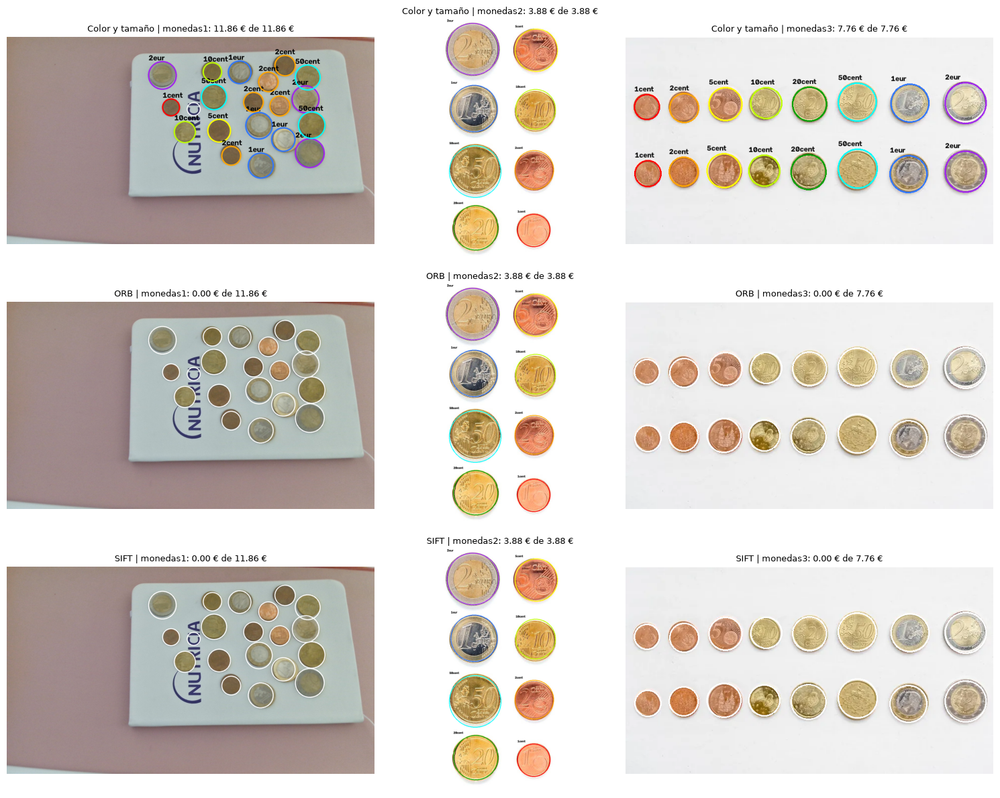

In [105]:
KEYPOINT_SIZE = 200
KEYPOINT_ZOOM = 0.65
RATIO = 0.8
RANSAC_PX = 4.0
MIN_INLIERS = 8

DETECTORS = {"ORB": cv2.ORB_create(nfeatures=1500), "SIFT": cv2.SIFT_create()}
NORMS = {"ORB": cv2.NORM_HAMMING, "SIFT": cv2.NORM_L2}


def coin_patch(gray):
    side = min(gray.shape[:2])
    half = int(round(KEYPOINT_ZOOM * side / 2))
    center_y, center_x = gray.shape[0] // 2, gray.shape[1] // 2
    patch = gray[center_y - half:center_y + half, center_x - half:center_x + half]
    return cv2.resize(patch, (KEYPOINT_SIZE, KEYPOINT_SIZE), interpolation=cv2.INTER_AREA)


def find_keypoints(gray, method):
    patch = coin_patch(apply_CLAHE(gray))
    return DETECTORS[method].detectAndCompute(patch, None)


def load_reference(name, method):
    image = cv2.cvtColor(cv2.imread(f"exercises/coins/Front{name}.jpg"), cv2.COLOR_BGR2RGB)
    return find_keypoints(to_gray(image), method)


REFERENCES = {method: [load_reference(name, method) for name in COINS["name"]] for method in DETECTORS}


def good_matches(coin_descriptors, reference_descriptors, method):
    pairs = cv2.BFMatcher(NORMS[method]).knnMatch(coin_descriptors, reference_descriptors, k=2)
    good = []
    for pair in pairs:
        if len(pair) == 2 and pair[0].distance < RATIO * pair[1].distance:
            good.append(pair[0])
    return good


def count_inliers(coin, reference, method):
    coin_keypoints, coin_descriptors = coin
    reference_keypoints, reference_descriptors = reference
    if coin_descriptors is None or reference_descriptors is None:
        return 0
    if len(coin_descriptors) < 2 or len(reference_descriptors) < 2:
        return 0

    matches = good_matches(coin_descriptors, reference_descriptors, method)
    if len(matches) < 3:
        return 0

    coin_points = np.float32([coin_keypoints[m.queryIdx].pt for m in matches])
    reference_points = np.float32([reference_keypoints[m.trainIdx].pt for m in matches])
    transform, inliers = cv2.estimateAffinePartial2D(coin_points, reference_points,
                                                     method=cv2.RANSAC, ransacReprojThreshold=RANSAC_PX)
    if transform is None:
        return 0
    return int(inliers.sum())


def classify_by_keypoints(img_rgb, coin, method):
    coin_features = find_keypoints(cut(to_gray(img_rgb), coin), method)
    inliers = [count_inliers(coin_features, reference, method) for reference in REFERENCES[method]]
    best = int(np.argmax(inliers))
    if inliers[best] < MIN_INLIERS:
        return None
    return best


def run_with_keypoints(img_rgb, method):
    coins, _ = run_pipeline(img_rgb)
    return coins, [classify_by_keypoints(img_rgb, coin, method) for coin in coins]


show_results([renamed(FINAL, "Color y tamaño"),
              experiment("ORB", run=run_with_keypoints, method="ORB"),
              experiment("SIFT", run=run_with_keypoints, method="SIFT")])

Se mantiene la clasificación por **color y tamaño**, descartando el uso de puntos característicos. Estos solo funcionan en `monedas2.jpg`, porque estas monedas fueron las usadas como referencia (unos 900 _inliers_ por moneda). En las otras dos imágenes no se acierta ninguna moneda, por dos motivos:

- **Dibujo en la cara:** al depender del país, no siempre coincide con la referencia.
- **Poco nivel de detalle:** las monedas pequeñas o desenfocadas tienen muy pocos puntos que comparar.